<a href="https://colab.research.google.com/github/dldustj0715/machine_learning/blob/main/week06/diabetes_deep_learning_1012.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Diabetes 딥러닝 실습

 (1) Outcome 이진 분류, (2) Outcome을 제외한 특성으로 BMI 회귀 예측



## 1. Google Drive 연결 및 라이브러리 불러오기

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

tf.keras.utils.set_random_seed(42)

Mounted at /content/drive


## 2. 데이터 불러오기 및 확인

In [2]:
path = '/content/drive/MyDrive/Colab Notebooks/diabetes.csv'
df = pd.read_csv(path)
print('데이터 크기:', df.shape)
print('컬럼:', df.columns.tolist())
display(df.head())
print('결측값 개수:')
print(df.isna().sum())

데이터 크기: (768, 9)
컬럼: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


결측값 개수:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


## Part A. Classification — Outcome 예측

`Outcome`을 정답으로 사용하며 나머지 8개 열을 입력으로 사용합니다. 출력층은 sigmoid, 손실함수는 binary_crossentropy입니다.

### A-1. 입력과 정답 분리, 학습/테스트 분리, 표준화

In [3]:
X_cls = df.drop(columns=['Outcome']).values
y_cls = df['Outcome'].values

X_cls_train, X_cls_test, y_cls_train, y_cls_test = train_test_split(
    X_cls, y_cls, test_size=0.2, random_state=42, stratify=y_cls
)
scaler_cls = StandardScaler()
X_cls_train = scaler_cls.fit_transform(X_cls_train)
X_cls_test = scaler_cls.transform(X_cls_test)
print('Train:', X_cls_train.shape, 'Test:', X_cls_test.shape)

Train: (614, 8) Test: (154, 8)


### A-2. 딥러닝 모델 생성 및 설정

In [4]:
classification_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(8,)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])
classification_model.compile(
    optimizer='adam', loss='binary_crossentropy', metrics=['accuracy']
)
classification_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 833 (3.25 KB)

 Trainable params: 833 (3.25 KB)

 Non-trainable params: 0 (0.00 B)

### A-3. 학습

In [5]:
history_cls = classification_model.fit(
    X_cls_train, y_cls_train,
    epochs=30, batch_size=32, validation_split=0.2, verbose=1
)

Epoch 1/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.5825 - loss: 0.7016 - val_accuracy: 0.5691 - val_loss: 0.6726
Epoch 2/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6273 - loss: 0.6560 - val_accuracy: 0.6098 - val_loss: 0.6319
Epoch 3/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6517 - loss: 0.6220 - val_accuracy: 0.6341 - val_loss: 0.6000
Epoch 4/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6741 - loss: 0.5943 - val_accuracy: 0.6341 - val_loss: 0.5745
Epoch 5/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6741 - loss: 0.5713 - val_accuracy: 0.6585 - val_loss: 0.5536
Epoch 6/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6802 - loss: 0.5515 - val_accuracy: 0.6585 - val_loss: 0.5366
Epoch 7/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7026 - loss: 0.5345 - val_accuracy: 0.6992 - val_loss: 0.5228
Epoch 8/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7210 - loss: 0.5198 - val_accuracy: 0.7317 - val_loss

### A-4. 평가 및 예측

In [6]:
cls_loss, cls_acc = classification_model.evaluate(X_cls_test, y_cls_test, verbose=0)
cls_prob = classification_model.predict(X_cls_test, verbose=0).flatten()
cls_pred = (cls_prob >= 0.5).astype(int)
print(f'Test Loss: {cls_loss:.4f}')
print(f'Test Accuracy: {cls_acc:.4f}')
print('Confusion Matrix:')
print(confusion_matrix(y_cls_test, cls_pred))
print('Classification Report:')
print(classification_report(y_cls_test, cls_pred, zero_division=0))

Test Loss: 0.4939
Test Accuracy: 0.7403
Confusion Matrix:
[[79 21]
 [19 35]]
Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.79      0.80       100
           1       0.62      0.65      0.64        54

    accuracy                           0.74       154
   macro avg       0.72      0.72      0.72       154
weighted avg       0.74      0.74      0.74       154



### A-5. 정확도 변화 그래프

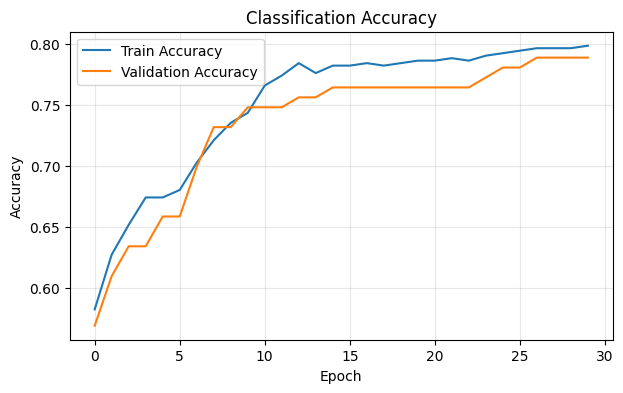

In [7]:
plt.figure(figsize=(7, 4))
plt.plot(history_cls.history['accuracy'], label='Train Accuracy')
plt.plot(history_cls.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.title('Classification Accuracy')
plt.legend(); plt.grid(alpha=0.3); plt.show()

## Part B. Regression — BMI 예측

`Outcome`과 정답인 `BMI`를 입력에서 제거합니다. 나머지 7개 열로 BMI의 연속적인 값을 예측합니다. 출력층은 None, 손실함수는 mse입니다.

### B-1. 입력과 정답 분리, 학습/테스트 분리, 표준화

In [8]:
X_reg = df.drop(columns=['Outcome', 'BMI']).values
y_reg = df['BMI'].values

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)
scaler_reg = StandardScaler()
X_reg_train = scaler_reg.fit_transform(X_reg_train)
X_reg_test = scaler_reg.transform(X_reg_test)
print('Train:', X_reg_train.shape, 'Test:', X_reg_test.shape)

Train: (614, 7) Test: (154, 7)


### B-2. 딥러닝 모델 생성 및 설정

In [14]:
regression_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(7,)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(1)
])
regression_model.compile(optimizer='adam', loss='mse', metrics=['mae'])
regression_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 32)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 801 (3.13 KB)

 Trainable params: 801 (3.13 KB)

 Non-trainable params: 0 (0.00 B)

### B-3. 학습

In [15]:
history_reg = regression_model.fit(
    X_reg_train, y_reg_train,
    epochs=100, batch_size=32, validation_split=0.2, verbose=1
)

Epoch 1/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 1056.4221 - mae: 31.5464 - val_loss: 1067.1908 - val_mae: 31.9009
Epoch 2/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1024.5249 - mae: 31.0574 - val_loss: 1032.3311 - val_mae: 31.3540
Epoch 3/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 985.1795 - mae: 30.4422 - val_loss: 988.2423 - val_mae: 30.6478
Epoch 4/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 935.3580 - mae: 29.6415 - val_loss: 933.3643 - val_mae: 29.7433
Epoch 5/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 873.4985 - mae: 28.6128 - val_loss: 865.2719 - val_mae: 28.5765
Epoch 6/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 797.9826 - mae: 27.2967 - val_loss: 783.2832 - val_mae: 27.0950
Epoch 7/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 708.3468 - mae: 25.6331 - val_loss: 687.9169 - val_mae: 25.2498
Epoch 8/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 606.8352 - mae: 23.5831 - val_loss: 582.4245 - val_mae: 23.0164
Epoch 9/100

### B-4. 평가 및 실제 BMI와 예측 BMI 비교

In [16]:
reg_mse, reg_mae = regression_model.evaluate(X_reg_test, y_reg_test, verbose=0)
reg_pred = regression_model.predict(X_reg_test, verbose=0).flatten()
reg_r2 = r2_score(y_reg_test, reg_pred)
print(f'Test MSE: {reg_mse:.4f}')
print(f'Test MAE: {reg_mae:.4f}')
print(f'Test R²: {reg_r2:.4f}')
display(pd.DataFrame({'Actual BMI': y_reg_test, 'Predicted BMI': reg_pred}).head(10))

Test MSE: 67.2168
Test MAE: 5.6494
Test R²: 0.0544


,Actual BMI,Predicted BMI
0,34.0,31.194550
1,35.7,34.853352
2,30.8,29.248852
3,24.6,32.900459
4,29.9,30.175673
5,37.7,31.619720
6,20.4,24.306044
7,33.8,24.992193
8,31.3,29.936039
9,33.7,27.957754


### B-5. 학습 손실 및 예측 결과 시각화

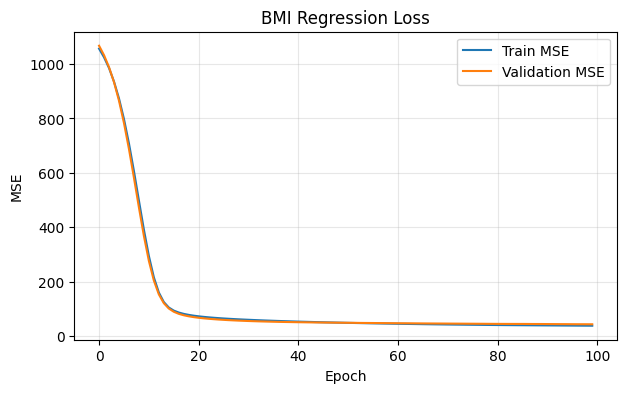

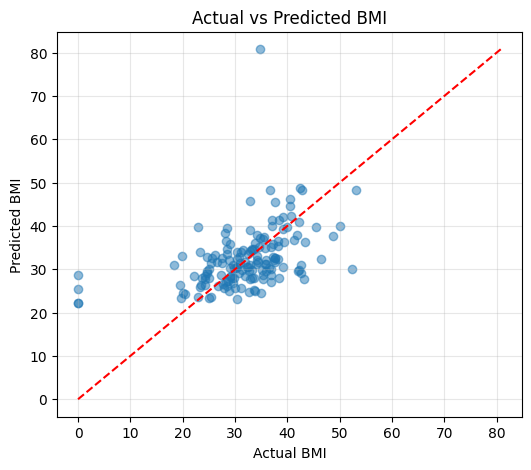

In [17]:
plt.figure(figsize=(7, 4))
plt.plot(history_reg.history['loss'], label='Train MSE')
plt.plot(history_reg.history['val_loss'], label='Validation MSE')
plt.xlabel('Epoch'); plt.ylabel('MSE'); plt.title('BMI Regression Loss')
plt.legend(); plt.grid(alpha=0.3); plt.show()

plt.figure(figsize=(6, 5))
plt.scatter(y_reg_test, reg_pred, alpha=0.5)
low = min(y_reg_test.min(), reg_pred.min())
high = max(y_reg_test.max(), reg_pred.max())
plt.plot([low, high], [low, high], 'r--')
plt.xlabel('Actual BMI'); plt.ylabel('Predicted BMI')
plt.title('Actual vs Predicted BMI'); plt.grid(alpha=0.3); plt.show()